In [1]:
from vocab_config import get_vocabulary
import torch
from doctr.models import crnn_vgg16_bn
from doctr.models import recognition_predictor, ocr_predictor
from doctr.io import DocumentFile

# Load the checkpoint
checkpoint = torch.load('models/best_model.pth', map_location="cpu")

# Initialize the model with the same vocabulary used during training
reco_model = crnn_vgg16_bn(
    pretrained=False, 
    pretrained_backbone=False,
    vocab=get_vocabulary()  # Use the same vocabulary as training
)

# Load only the model's state dictionary
reco_model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [11]:
# Create the predictor
predictor = ocr_predictor(det_arch="db_resnet50", reco_arch=reco_model, pretrained=True)
reco_predictor = recognition_predictor(reco_model, pretrained=True)

(-0.5, 123.5, 49.5, -0.5)

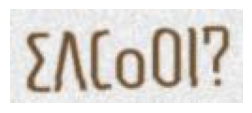

In [18]:
import matplotlib.pyplot as plt

image_path = "data/images/test/1.jpg"
input_page = DocumentFile.from_images(image_path)[0]

# Display the input image
plt.figure(figsize=(3, 3))
plt.imshow(input_page)
plt.axis('off')

In [19]:
out = reco_predictor([input_page])
print(f"Prediction: {out[0][0]}\nConfidence: {out[0][1]:.2f}")

Prediction: ⵉⴷⵎⴰⵔⵏ?
Confidence: 0.79


In [45]:
image_path = "image.png"
input_page = DocumentFile.from_images(image_path)
output = predictor(input_page)

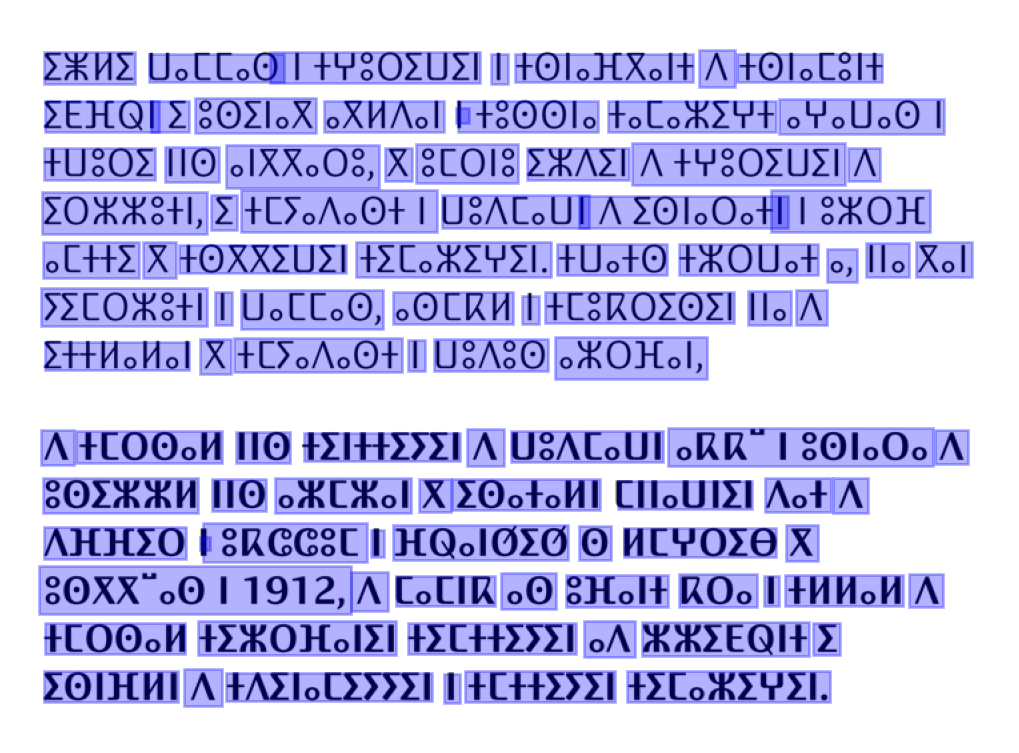

In [46]:
output.show()

In [47]:
res = ""
for obj in output.pages:
    for obj1 in obj.blocks:
        for obj2 in obj1.lines:
            for obj3 in obj2.words:
                res = res + " " + obj3.value
            res = res + "\n"
        res = res + "\n"
print(res)

 ⵉⵥⵍⵉ ⵡⴰⵎⵎⴰⵙ ⵜⵜⵖⵓⵔⵉⵡⵉ ⵏ ⵜⵙⵏⴰⵃⴰⵏⵜ ⴷ ⵜⵙⵏⴰⵎⵏⵜ
 ⵉⴹⴼⵕⵏ ⵉ ⵓⵙⵉⵏⴰⴳ ⴰⵃⵍⴷⴰⵏ ⵏ ⵜⵓⵙⵙⵏⴰ ⵜⴰⵎⴰⵣⵉⵖⵜ ⴰⵖⴰⵡⴰⵙⵏ
 ⵜⵡⴻⵔⵉ ⵏⵏⵙ ⴰⵏⴳⴳⴰⵔⵓ, ⴳ ⵓⵎⵔⵏⵓ ⵉⵣⴷⵉⵏ ⴷⵜⵖⵓⵔⵉⵡⵉⵏ ⴷ
 ⵉⵔⵣⵣⵓⵜⵏ, ⵉ ⵜⵎⵢⴰⴷⴰⵙⵜⵏ ⵡⵓⴷⵎⴰⵡⵏ ⵄⵉⵙⴰⵔⴰⵜ ⵏⵏⵓⵣⵔⴼ
 ⴰⵎⵜⵜⵉ ⴳ ⵜⵙⵅⵉⵡⵉ ⵜⵉⵎⴰⵣⵉⵖⵉⵏ. ⵜⵡⴰⵜⵙ ⵜⵣⵔⵡⴰⵜ ⴰ, ⵏⵏⴰ ⴳⴰⵏ
 ⵢⵉⵎⵔⵣⵓⵜⵏ ⵏ ⵡⴰⵎⵎⴰⵙ, ⴰⵙⵎⴽⵍ ⵏ ⵜⵎⵓⴽⵔⵉⵙⵉ ⵏⵏⴰ ⴷ
 ⵉⵜⵜⵍⴰⵍⴰ ⴳ ⵜⵎⵢⴰⴷⴰⵙⵜ ⵏ ⵡⵓⴷⵓⵙ ⴰⵣⵔⴼⴰⵏ,
 ⴷ ⵜⵎⵔⵙⴰⵍ ⵏⵏⵙ ⵜⵉⵜⵉⵉ ⴷ ⵡⵓⴷⵎⴰⵡⵏ ⴰⴽⴽⵏⵓⵙⵏⴰⵔⴰ ⴷ
 ⵓⵙⵉⵣⵣⵍ ⵏⵏⵙ ⴰⵣⵎⵣⴰⵏ ⴳ ⵉⵙⴰⵜⴰⵍ! ⵎⵏⵏⴰⵡⵉ ⴷⴰⵜ ⴷ
 ⴷⴼⴼⵉⵔ ⵏ ⵏⵓⴽⵛⵛⵓⵎ ⵏ ⴼⵕⴰⵏⵚⵉⵚ ⵙ ⵍⵎⵖⵙⵉⴻ ⴳ
 ⵓⴱⵅⴰⵙⵏⵏⴻⵏⵉ ⴷ ⵎⴰⵎⵏⴽ ⴰⵙ ⴻⴼⴰⵏⵜ ⴽⵔⴰ ⵏ ⵜⵍⵍⴰⵍ ⴷ
 ⵜⵎⵔⵙⴰⵍ ⵜⵉⵣⵔⴼⴰⵏⵉⵏ ⵜⵉⵎⵜⵜⵉⵉⵏ ⴰⴷ ⵣⵣⵉⴹⵕⵏⵜ ⵉ
 ⵉⵙⵏⴼⵍⵏ ⴷ ⵜⵄ ⵏ ⵜⵎⵜⵜⵉⵢⵉⵏ ⵜⵉⵎⴰⵣⵉⵖⵉⵏ.


